# 02 - Preparação de Dados: Replicação Benabderrahmane et al. (2024)

> **Iniciação Científica (IC) em Engenharia de Computação**  
> **Tema:** Detecção / Triagem de Transtorno do Espectro Autista (TEA) via Eye-Tracking e Deep Learning  
> **Objetivo Desta Etapa:** Carregamento ultrarrápido dos dados consolidados em Parquet e agrupamento por `(Participant, Stimulus)`.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Resolução de diretórios
CURRENT_DIR = Path.cwd()
DATA_DIR = CURRENT_DIR.parent / "data" if (CURRENT_DIR.parent / "data").exists() else CURRENT_DIR / "data"
PARQUET_PATH = DATA_DIR / "processed" / "cilia_clean.parquet"

print(f"Carregando dados limpos de: {PARQUET_PATH.resolve()}")
df = pd.read_parquet(PARQUET_PATH)

print(f"Total de registros carregados: {len(df):,}")
print(f"Colunas disponíveis: {list(df.columns)}")
display(df.head(5))

Carregando dados limpos de: /home/raphaell-arcanjo/Documents/ic-eye-tracking/data/processed/cilia_clean.parquet
Total de registros carregados: 1,351,157
Colunas disponíveis: ['Participant', 'Stimulus', 'RecordingTime [ms]', 'x_clean', 'y_clean', 'valid_mask', 'Category Right', 'Class']


,Participant,Stimulus,RecordingTime [ms],x_clean,y_clean,valid_mask,Category Right,Class
0,1,1 coucou D.jpg,277330.360,0.000000,0.000000,0.0,Separator,ASD
1,1,1 coucou D.jpg,277337.015,0.496658,0.370705,1.0,Fixation,ASD
2,1,1 coucou D.jpg,277356.895,0.492286,0.359088,1.0,Fixation,ASD
3,1,1 coucou D.jpg,277376.893,0.492396,0.372545,1.0,Fixation,ASD
4,1,1 coucou D.jpg,277396.768,0.502536,0.372458,1.0,Fixation,ASD


In [2]:
# Agrupamento estrito pelas séries de cada participante e estímulo
grouped = df.groupby(['Participant', 'Stimulus'], sort=False)
n_groups = grouped.ngroups

print("=" * 80)
print(f"TOTAL DE PARES ÚNICOS (PARTICIPANT, STIMULUS): {n_groups} amostras")
print("=" * 80)

# Distribuição dos tipos de movimentos oculares em Category Right
print("\nDistribuição dos tipos de movimentos em 'Category Right':")
cat_counts = df['Category Right'].value_counts()
cat_pcts = df['Category Right'].value_counts(normalize=True) * 100
df_cat = pd.DataFrame({
    'Ocorrências': cat_counts,
    'Proporção (%)': cat_pcts.round(2)
})
display(df_cat)

# Resumo dos primeiros 10 grupos
summary_rows = []
for idx, ((pid, stim), group) in enumerate(grouped):
    if idx >= 10:
        break
    summary_rows.append({
        'Participant': pid,
        'Class': group['Class'].iloc[0],
        'Stimulus': stim,
        'Total Quadros': len(group),
        'Duração Aprox (s)': round(len(group) / 50.0, 2),
        'Fixações': (group['Category Right'] == 'Fixation').sum(),
        'Sacadas': (group['Category Right'] == 'Saccade').sum(),
        'Blinks': (group['Category Right'] == 'Blink').sum(),
        'Taxa Sinal Válido (%)': round(group['valid_mask'].mean() * 100, 2)
    })

df_groups_summary = pd.DataFrame(summary_rows)
print("\nTabela de Resumo dos Primeiros 10 Grupos (Participant, Stimulus):")
display(df_groups_summary)

TOTAL DE PARES ÚNICOS (PARTICIPANT, STIMULUS): 2372 amostras

Distribuição dos tipos de movimentos em 'Category Right':


,Ocorrências,Proporção (%)
Category Right,,
Fixation,890326,65.89
Blink,224904,16.65
Saccade,147318,10.90
Unclassified,85053,6.29
Separator,3555,0.26
Left Click,1,0.00



Tabela de Resumo dos Primeiros 10 Grupos (Participant, Stimulus):


,Participant,Class,Stimulus,Total Quadros,Duração Aprox (s),Fixações,Sacadas,Blinks,Taxa Sinal Válido (%)
0,1,ASD,1 coucou D.jpg,147,2.94,116,29,0,99.320000
1,1,ASD,11 yeux chat D.jpg,88,1.76,18,12,52,48.860001
2,1,ASD,11 yeux chat gauche.jpg,147,2.94,46,20,78,51.700001
3,1,ASD,12 tete chat droite.jpg,66,1.32,0,0,0,0.000000
4,1,ASD,12 tete chat gauche.jpg,125,2.50,89,20,11,91.199997
5,1,ASD,13 tete pointage chat droite.jpg,67,1.34,0,0,0,0.000000
6,1,ASD,13 tete pointage chat gauche.jpg,147,2.94,132,14,0,99.320000
7,1,ASD,14 devant point chat droite.jpg,67,1.34,0,0,0,0.000000
8,1,ASD,14 devant point chat gauche.jpg,147,2.94,136,10,0,99.320000
9,1,ASD,15 devant - Copie.jpg,95,1.90,34,2,44,68.419998


## Etapa 2: Filtragem de Grupos Sem Sinal e Geração do Scan-path Map (600x400)

1. **Filtro de Grupos sem Sinal:** Descarte de grupos `(Participant, Stimulus)` onde `valid_mask` soma 0 ou onde há menos de 2 pontos válidos com `Category Right` em `['Fixation', 'Saccade']`.
2. **Geração do Scan-path Map (600x400):** Construção da imagem 2D em escala de cinza (fundo branco = 255, traços e nós pretos = 0) conectando pontos válidos consecutivos e destacando fixações.
3. **Inspeção Visual:** Comparação visual entre uma amostra real do grupo **ASD** e uma do grupo **TD**.

In [3]:
# 1. Filtro de Grupos sem Sinal
valid_groups = {}
discarded_groups = 0

for (pid, stim), group in grouped:
    # Pontos válidos com movimento ocular relevante (Fixation ou Saccade)
    valid_points = group[
        (group['valid_mask'] == 1.0) &
        (group['Category Right'].isin(['Fixation', 'Saccade']))
    ]
    if group['valid_mask'].sum() > 0 and len(valid_points) >= 2:
        valid_groups[(pid, stim)] = group
    else:
        discarded_groups += 1

print("=" * 80)
print(f"Total de grupos originais : {n_groups}")
print(f"Grupos descartados (s/ sinal): {discarded_groups}")
print(f"Grupos válidos restantes  : {len(valid_groups)} ({len(valid_groups)/n_groups*100:.2f}%)")
print("=" * 80)

Total de grupos originais : 2372
Grupos descartados (s/ sinal): 257
Grupos válidos restantes  : 2115 (89.17%)


In [4]:
from PIL import Image, ImageDraw

# 2. Função de Geração do Scan-path Map (600x400)
def generate_scanpath_image(group_df: pd.DataFrame, width: int = 600, height: int = 400) -> np.ndarray:
    """
    Gera o Scan-path Map 2D (height=400, width=600) seguindo Benabderrahmane et al. (2024).
    Fundo branco (255), trajetória sacádica como linhas pretas finas (0) entre pontos válidos
    consecutivos e pequenos círculos preenchidos (0) nos pontos de 'Fixation'.
    """
    # Imagem em escala de cinza ('L') com fundo branco (255), dimensão (width=600, height=400) -> array (400, 600)
    img = Image.new('L', (width, height), color=255)
    draw = ImageDraw.Draw(img)
    
    # Filtra apenas linhas com sinal válido
    valid_df = group_df[group_df['valid_mask'] == 1.0]
    if len(valid_df) == 0:
        return np.array(img, dtype=np.uint8)
    
    # Converte coordenadas normalizadas [0, 1] para escala da imagem com clip em [0, width-1] e [0, height-1]
    px = np.clip((valid_df['x_clean'].to_numpy() * width).astype(int), 0, width - 1)
    py = np.clip((valid_df['y_clean'].to_numpy() * height).astype(int), 0, height - 1)
    categories = valid_df['Category Right'].to_numpy()
    
    # Desenha linhas pretas finas conectando pontos válidos consecutivos (trajetória sacádica)
    points = list(zip(px.tolist(), py.tolist()))
    if len(points) >= 2:
        draw.line(points, fill=0, width=1)
    
    # Desenha pequenos círculos/nós preenchidos nos pontos classificados como 'Fixation'
    radius = 3
    for (x, y), cat in zip(points, categories):
        if cat == 'Fixation':
            draw.ellipse([x - radius, y - radius, x + radius, y + radius], fill=0, outline=0)
            
    return np.array(img, dtype=np.uint8)

Inspeção dos Tensores / Imagens Geradas:
[ASD] Amostra (1, '1 coucou D.jpg') -> shape: (400, 600), dtype: uint8, min: 0, max: 255
[TD]  Amostra (32, '1 coucou D.jpg') -> shape: (400, 600), dtype: uint8, min: 0, max: 255


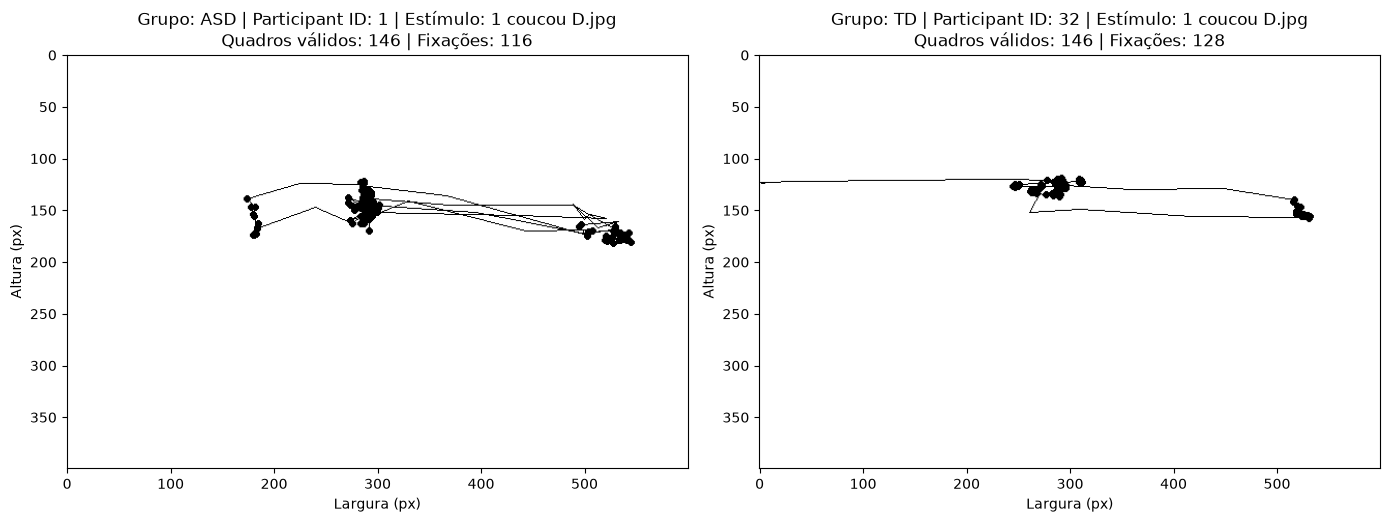

In [5]:
import matplotlib.pyplot as plt

# 3. Inspeção Visual Obrigatória: 1 exemplo ASD e 1 exemplo TD no mesmo estímulo estático ('1 coucou D.jpg')
target_stimulus = '1 coucou D.jpg'
asd_key, asd_df = None, None
td_key, td_df = None, None

for (pid, stim), g in valid_groups.items():
    if stim != target_stimulus:
        continue
    valid_rate = g['valid_mask'].mean()
    n_fix = ((g['valid_mask'] == 1.0) & (g['Category Right'] == 'Fixation')).sum()
    cls = g['Class'].iloc[0]
    if cls == 'ASD' and asd_df is None and valid_rate >= 0.85 and n_fix >= 80:
        asd_key, asd_df = (pid, stim), g
    elif cls == 'TD' and td_df is None and valid_rate >= 0.85 and n_fix >= 80:
        td_key, td_df = (pid, stim), g
    if asd_df is not None and td_df is not None:
        break

scanpath_asd = generate_scanpath_image(asd_df, width=600, height=400)
scanpath_td = generate_scanpath_image(td_df, width=600, height=400)

print("Inspeção dos Tensores / Imagens Geradas:")
print(f"[ASD] Amostra {asd_key} -> shape: {scanpath_asd.shape}, dtype: {scanpath_asd.dtype}, min: {scanpath_asd.min()}, max: {scanpath_asd.max()}")
print(f"[TD]  Amostra {td_key} -> shape: {scanpath_td.shape}, dtype: {scanpath_td.dtype}, min: {scanpath_td.min()}, max: {scanpath_td.max()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

n_valid_asd = int((asd_df['valid_mask'] == 1.0).sum())
n_fix_asd = int(((asd_df['valid_mask'] == 1.0) & (asd_df['Category Right'] == 'Fixation')).sum())
axes[0].imshow(scanpath_asd, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(
    f"Grupo: ASD | Participant ID: {asd_key[0]} | Estímulo: {asd_key[1]}\n"
    f"Quadros válidos: {n_valid_asd} | Fixações: {n_fix_asd}"
)
axes[0].set_xlabel("Largura (px)")
axes[0].set_ylabel("Altura (px)")

n_valid_td = int((td_df['valid_mask'] == 1.0).sum())
n_fix_td = int(((td_df['valid_mask'] == 1.0) & (td_df['Category Right'] == 'Fixation')).sum())
axes[1].imshow(scanpath_td, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(
    f"Grupo: TD | Participant ID: {td_key[0]} | Estímulo: {td_key[1]}\n"
    f"Quadros válidos: {n_valid_td} | Fixações: {n_fix_td}"
)
axes[1].set_xlabel("Largura (px)")
axes[1].set_ylabel("Altura (px)")

plt.tight_layout()
plt.show()

## Etapa 3: Extração das Sequências Numéricas, Padding e Escalares

1. **Sequência de Distâncias Euclidianas:** Calculada sobre pontos válidos ordenados (`valid_mask == 1.0`) entre coordenadas consecutivas $\sqrt{(x_t - x_{t-1})^2 + (y_t - y_{t-1})^2}$, com *zero-padding* até `10.370` elementos (`float32`).
2. **Sequência de Durações de Eventos:** Blocos contíguos de `Category Right` em `['Fixation', 'Saccade']`, calculando a duração em milissegundos (`RecordingTime [ms]` final $-$ inicial de cada bloco), com *zero-padding* até `1.313` elementos (`float32`).
3. **Escalares:** `Fixation Rate` (proporção do tempo total em fixações sobre a duração total válida do estímulo), `Stimulus ID` (mapeamento inteiro dos estímulos) e `Class Label` (`0` = TD, `1` = ASD).

In [6]:
# Mapeamento numérico inteiro para os estímulos (Stimulus ID) e Classes (0 = TD, 1 = ASD)
unique_stimuli = sorted(df['Stimulus'].unique())
stimulus_to_id = {stim: idx for idx, stim in enumerate(unique_stimuli)}
class_to_label = {'TD': 0, 'ASD': 1}

print(f"Total de estímulos únicos mapeados: {len(stimulus_to_id)}")
print("Exemplo dos 5 primeiros Stimulus IDs:", list(stimulus_to_id.items())[:5])

MAX_DIST_LEN = 10370
MAX_DUR_LEN = 1313

def extract_group_features(
    group_df: pd.DataFrame,
    stim_map: dict = stimulus_to_id,
    max_dist_len: int = MAX_DIST_LEN,
    max_dur_len: int = MAX_DUR_LEN
) -> dict:
    """
    Extrai as sequências numéricas com zero-padding e os escalares de um grupo (Participant, Stimulus).
    """
    # Ordena cronologicamente por segurança
    g = group_df.sort_values('RecordingTime [ms]', kind='mergesort')
    
    # 1. Sequência de Distâncias Euclidianas (apenas pontos válidos)
    valid_df = g[g['valid_mask'] == 1.0]
    if len(valid_df) >= 2:
        x = valid_df['x_clean'].to_numpy(dtype=np.float32)
        y = valid_df['y_clean'].to_numpy(dtype=np.float32)
        dx = np.diff(x)
        dy = np.diff(y)
        distances = np.sqrt(dx**2 + dy**2).astype(np.float32)
    else:
        distances = np.array([], dtype=np.float32)
        
    # Truncamento preventivo caso exceda e zero-padding ao final até 10.370
    distances = distances[:max_dist_len]
    pad_dist = max_dist_len - len(distances)
    distances_padded = np.pad(distances, (0, pad_dist), mode='constant', constant_values=0.0).astype(np.float32)
    
    # 2. Sequência de Durações de Eventos (blocos contíguos de 'Fixation' e 'Saccade')
    cats = g['Category Right']
    block_ids = (cats != cats.shift()).cumsum()
    
    durations_list = []
    fixation_time_ms = 0.0
    
    for _, block in g.groupby(block_ids, sort=False):
        cat = block['Category Right'].iloc[0]
        if cat in ('Fixation', 'Saccade'):
            t_start = float(block['RecordingTime [ms]'].iloc[0])
            t_end = float(block['RecordingTime [ms]'].iloc[-1])
            dur = max(0.0, t_end - t_start)
            durations_list.append(dur)
            if cat == 'Fixation':
                fixation_time_ms += dur
                
    durations = np.array(durations_list[:max_dur_len], dtype=np.float32)
    pad_dur = max_dur_len - len(durations)
    durations_padded = np.pad(durations, (0, pad_dur), mode='constant', constant_values=0.0).astype(np.float32)
    
    # 3. Escalares
    # Duração total válida do estímulo (tempo total dos eventos válidos ou janela válida do estímulo)
    total_valid_event_time = float(durations.sum())
    if total_valid_event_time > 0.0:
        fixation_rate = float(fixation_time_ms / total_valid_event_time)
    elif len(valid_df) > 0:
        fixation_rate = float((valid_df['Category Right'] == 'Fixation').mean())
    else:
        fixation_rate = 0.0
        
    stim_name = g['Stimulus'].iloc[0]
    stimulus_id = int(stim_map[stim_name])
    class_label = int(class_to_label[g['Class'].iloc[0]])
    
    return {
        'distances': distances_padded,
        'durations': durations_padded,
        'fixation_rate': fixation_rate,
        'stimulus_id': stimulus_id,
        'label': class_label
    }

Total de estímulos únicos mapeados: 148
Exemplo dos 5 primeiros Stimulus IDs: [('01 coucou g.jpg', 0), ('01 neutre2.avi', 1), ('01 neutre22.avi', 2), ('01 neutre3.avi', 3), ('01vnvg151201b1.avi', 4)]


In [7]:
# 2. Célula de Teste e Inspeção (1 amostra ASD e 1 amostra TD)
features_asd = extract_group_features(asd_df)
features_td = extract_group_features(td_df)

for group_name, key, feat in [("ASD", asd_key, features_asd), ("TD", td_key, features_td)]:
    dist_arr = feat['distances']
    dur_arr = feat['durations']
    
    dist_nonzero = dist_arr[dist_arr > 0]
    dur_nonzero = dur_arr[dur_arr > 0]
    
    print("=" * 85)
    print(f"INSPEÇÃO DA AMOSTRA [{group_name}] -> Participant: {key[0]} | Stimulus: '{key[1]}'")
    print("=" * 85)
    print(f"Shape Array de Distâncias : {dist_arr.shape} | dtype: {dist_arr.dtype}")
    print(f"Shape Array de Durações   : {dur_arr.shape}  | dtype: {dur_arr.dtype}")
    print(f"Fixation Rate (float)     : {feat['fixation_rate']:.4f} ({type(feat['fixation_rate']).__name__})")
    print(f"Stimulus ID (int)         : {feat['stimulus_id']} ({type(feat['stimulus_id']).__name__})")
    print(f"Class Label (int)         : {feat['label']} ({type(feat['label']).__name__})")
    print("-" * 85)
    print(f"Distâncias -> 10 primeiros não-nulos : {np.round(dist_nonzero[:10], 5)}")
    print(f"Distâncias -> 5 últimos (padding)    : {dist_arr[-5:]}")
    print(f"Durações   -> 10 primeiros não-nulos : {np.round(dur_nonzero[:10], 3)}")
    print(f"Durações   -> 5 últimos (padding)    : {dur_arr[-5:]}\n")

INSPEÇÃO DA AMOSTRA [ASD] -> Participant: 1 | Stimulus: '1 coucou D.jpg'
Shape Array de Distâncias : (10370,) | dtype: float32
Shape Array de Durações   : (1313,)  | dtype: float32
Fixation Rate (float)     : 0.8524 (float)
Stimulus ID (int)         : 35 (int)
Class Label (int)         : 1 (int)
-------------------------------------------------------------------------------------
Distâncias -> 10 primeiros não-nulos : [0.01241 0.01346 0.01014 0.00973 0.01282 0.01779 0.03499 0.05207 0.03726
 0.04112]
Distâncias -> 5 últimos (padding)    : [0. 0. 0. 0. 0.]
Durações   -> 10 primeiros não-nulos : [159.125 119.275 159.106 139.127  79.628  39.749 238.628  39.745 139.248
  59.748]
Durações   -> 5 últimos (padding)    : [0. 0. 0. 0. 0.]

INSPEÇÃO DA AMOSTRA [TD] -> Participant: 32 | Stimulus: '1 coucou D.jpg'
Shape Array de Distâncias : (10370,) | dtype: float32
Shape Array de Durações   : (1313,)  | dtype: float32
Fixation Rate (float)     : 0.9166 (float)
Stimulus ID (int)         : 35 (int)

## Etapa 4: Empacotamento em PyTorch (`Dataset` e `DataLoader`)

1. **`BenabderrahmaneDataset(torch.utils.data.Dataset)`:** Empacota os grupos válidos `(Participant, Stimulus)` retornando tensores prontos para a arquitetura multimodal (Scan-path 2D + Sequências 1D + Escalares + Rótulo e `participant_id` para validação cruzada *Leave-One-Subject-Out* — LOSO-CV).
2. **Validação com `DataLoader`:** Inspeção de 1 *batch* (`batch_size=2`) verificando os `shapes` e `dtypes` de todas as chaves do dicionário.

In [8]:
import torch
from torch.utils.data import Dataset, DataLoader

# 1. Classe PyTorch CustomDataset
class BenabderrahmaneDataset(Dataset):
    """
    Dataset PyTorch multimodal seguindo Benabderrahmane et al. (2024).
    Recebe a lista de chaves de grupos válidos pré-filtrados e o DataFrame processado (ou dicionário de grupos).
    """
    def __init__(
        self,
        valid_keys: list,
        df_processed: pd.DataFrame,
        groups_dict: dict = None,
        stim_map: dict = stimulus_to_id
    ):
        self.valid_keys = list(valid_keys)
        self.stim_map = stim_map
        
        if groups_dict is not None:
            self.groups = groups_dict
        else:
            grouped_df = df_processed.groupby(['Participant', 'Stimulus'], sort=False)
            self.groups = {k: grouped_df.get_group(k) for k in self.valid_keys}

    def __len__(self) -> int:
        return len(self.valid_keys)

    def __getitem__(self, idx: int) -> dict:
        pid, stim = self.valid_keys[idx]
        group_df = self.groups[(pid, stim)]
        
        # Imagem de scan-path (400, 600) -> float32 em [0.0, 1.0] -> adiciona canal (1, 400, 600)
        scanpath_np = generate_scanpath_image(group_df, width=600, height=400).astype(np.float32) / 255.0
        scanpath_tensor = torch.from_numpy(scanpath_np).unsqueeze(0)  # shape: (1, 400, 600)
        
        # Extração das sequências numéricas e escalares
        feat = extract_group_features(group_df, stim_map=self.stim_map)
        
        distances_tensor = torch.from_numpy(feat['distances']).to(torch.float32)  # shape: (10370,)
        durations_tensor = torch.from_numpy(feat['durations']).to(torch.float32)  # shape: (1313,)
        scalars_tensor = torch.tensor(
            [feat['fixation_rate'], float(feat['stimulus_id'])],
            dtype=torch.float32
        )  # shape: (2,)
        
        label_tensor = torch.tensor(feat['label'], dtype=torch.long)
        participant_tensor = torch.tensor(int(pid), dtype=torch.long)
        
        return {
            'scanpath': scanpath_tensor,
            'distances': distances_tensor,
            'durations': durations_tensor,
            'scalars': scalars_tensor,
            'label': label_tensor,
            'participant_id': participant_tensor
        }

In [9]:
# 2. Teste e Validação com DataLoader
valid_keys_list = list(valid_groups.keys())
dataset = BenabderrahmaneDataset(
    valid_keys=valid_keys_list,
    df_processed=df,
    groups_dict=valid_groups
)

torch.manual_seed(42)
dataloader = DataLoader(dataset, batch_size=2, shuffle=True)

batch = next(iter(dataloader))

print("=" * 85)
print(f"VALIDAÇÃO DO DATASET E DATALOADER (Total de amostras no Dataset: {len(dataset)})")
print("=" * 85)
for k, v in batch.items():
    print(f"Chave: '{k:<14}' | shape: {str(tuple(v.shape)):<18} | dtype: {v.dtype}")
print("-" * 85)
print(f"Scanpath min/max no batch : min={batch['scanpath'].min().item():.4f}, max={batch['scanpath'].max().item():.4f}")
print(f"Scalars do batch          :\n{batch['scalars']}")
print(f"Labels do batch           : {batch['label']}")
print(f"Participant IDs do batch  : {batch['participant_id']}")

VALIDAÇÃO DO DATASET E DATALOADER (Total de amostras no Dataset: 2115)
Chave: 'scanpath      ' | shape: (2, 1, 400, 600)   | dtype: torch.float32
Chave: 'distances     ' | shape: (2, 10370)         | dtype: torch.float32
Chave: 'durations     ' | shape: (2, 1313)          | dtype: torch.float32
Chave: 'scalars       ' | shape: (2, 2)             | dtype: torch.float32
Chave: 'label         ' | shape: (2,)               | dtype: torch.int64
Chave: 'participant_id' | shape: (2,)               | dtype: torch.int64
-------------------------------------------------------------------------------------
Scanpath min/max no batch : min=0.0000, max=1.0000
Scalars do batch          :
tensor([[ 0.9646, 79.0000],
        [ 0.2728, 39.0000]])
Labels do batch           : tensor([1, 0])
Participant IDs do batch  : tensor([10, 42])
